# Student Performance Analysis (Mathematics, secondary school)

**Dataset:** UCI Student Performance dataset (student-mat.csv), 395 students from two
Portuguese secondary schools. Source: P. Cortez and A. Silva, "Using Data Mining to Predict
Secondary School Student Performance." This dataset is licensed under a Creative Commons Attribution 4.0 International (CC BY 4.0) license.

**Tools:** Python, pandas, Matplotlib

**Questions**
1. Do students with more absences tend to get lower final grades?
2. How does study time relate to the final grade?
3. Do students with past failures perform worse?
4. What share of students pass, and what do students who don't pass have in common?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv("student-mat.csv", sep=";")
df.shape

(395, 33)

In [2]:
df["passed"] = df["G3"] >= 10
df["passed"].mean() * 100

np.float64(67.08860759493672)

## Pass mark (project rule)

According to the dataset documentation, the final grade (G3) is a number from 0 to 20.
The documentation does not define a pass mark. For this project I define a pass as
**G3 >= 10**, the midpoint of the 0-20 scale. This is my own analytical rule,
not an official standard, and it is stored as a constant so it can be changed easily.

In [3]:
PASS_MARK = 10
for mark in [8, 10, 12]:
    print(mark, round((df["G3"] >= mark).mean() * 100, 2), "%")

8 82.28 %
10 67.09 %
12 41.01 %


In [4]:
df[df["G3"] == 0][["G1", "G2", "G3", "absences", "failures"]].head(10)

,G1,G2,G3,absences,failures
128,7,4,0,0,2
130,12,0,0,0,2
131,8,0,0,0,0
134,9,0,0,0,0
135,11,0,0,0,0
136,10,0,0,0,0
137,4,0,0,0,2
140,7,9,0,0,0
144,5,0,0,0,3
146,6,7,0,0,3


In [5]:
df.isnull().sum().sum()

np.int64(0)

In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
(df["G3"] == 0).sum()

np.int64(38)

## Data cleaning checks

- Missing values: 0
- Duplicate rows: 0
- Students with G3 = 0: 38 of 395 (about 9.6%)

The dataset has no missing values or duplicates, so no cleaning was needed for those.
The 38 zero final grades are examined below.

In [8]:
zero_final = df[df["G3"] == 0]
zero_final[["G1", "G2", "G3", "absences", "failures"]].head(10)

,G1,G2,G3,absences,failures
128,7,4,0,0,2
130,12,0,0,0,2
131,8,0,0,0,0
134,9,0,0,0,0
135,11,0,0,0,0
136,10,0,0,0,0
137,4,0,0,0,2
140,7,9,0,0,0
144,5,0,0,0,3
146,6,7,0,0,3


In [9]:
print("G3 = 0 and G2 > 0:", ((df["G3"] == 0) & (df["G2"] > 0)).sum())
print("G3 = 0 and G2 = 0:", ((df["G3"] == 0) & (df["G2"] == 0)).sum())

G3 = 0 and G2 > 0: 25
G3 = 0 and G2 = 0: 13


In [10]:
zero_final["absences"].describe()

count    38.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: absences, dtype: float64

In [11]:

df_no_zero = df[df["G3"] > 0]

print("All students:     ", len(df), "| pass rate:", round((df["G3"] >= PASS_MARK).mean() * 100, 2), "%")
print("Excluding G3 = 0: ", len(df_no_zero), "| pass rate:", round((df_no_zero["G3"] >= PASS_MARK).mean() * 100, 2), "%")
print("Absences vs G3 correlation (all):        ", round(df[["absences", "G3"]].corr().iloc[0, 1], 2))
print("Absences vs G3 correlation (excl. zeros):", round(df_no_zero[["absences", "G3"]].corr().iloc[0, 1], 2))

All students:      395 | pass rate: 67.09 %
Excluding G3 = 0:  357 | pass rate: 74.23 %
Absences vs G3 correlation (all):         0.03
Absences vs G3 correlation (excl. zeros): -0.21


## Handling students with a final grade of 0

38 of 395 students (9.6%) have G3 = 0. Of these, 25 had a G2 above 0 and 13 already
had a G2 of 0. All 38 have 0 recorded absences. The documentation does not explain
the zeros, so I cannot say whether these students left the course or did not sit the
final assessment.

Decision:
- Pass rate: reported both for all 395 students (67.09%) and excluding G3 = 0 (74.23%).
- Relationship analysis (absences, study time, failures): uses the 357 students with
  G3 > 0, because the zero-grade group has uniformly 0 absences and hides the pattern.
  The absences-grade correlation is 0.03 with all students but -0.21 without the zeros.

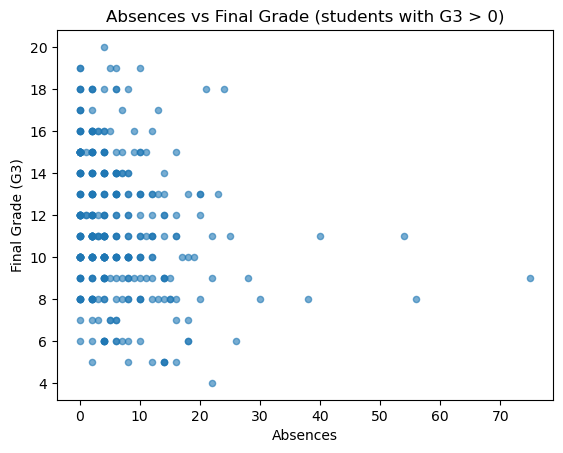

In [12]:
#1.Do students with more absences tend to get lower final grades?

df_no_zero.plot(kind="scatter", x="absences", y="G3", alpha=0.6)
plt.title("Absences vs Final Grade (students with G3 > 0)")
plt.xlabel("Absences")
plt.ylabel("Final Grade (G3)")
plt.show()

Among students with a final grade above 0 (n = 357), absences show a weak negative
association with the final grade (correlation = -0.21). Absences alone do not explain much
of the variation in grades.

In [13]:
#2.How does study time relate to the final grade?
df_no_zero.groupby("studytime")["G3"].agg(["count", "mean"]).round(2)

,count,mean
studytime,,
1,92,11.47
2,182,11.07
3,59,12.56
4,24,12.67


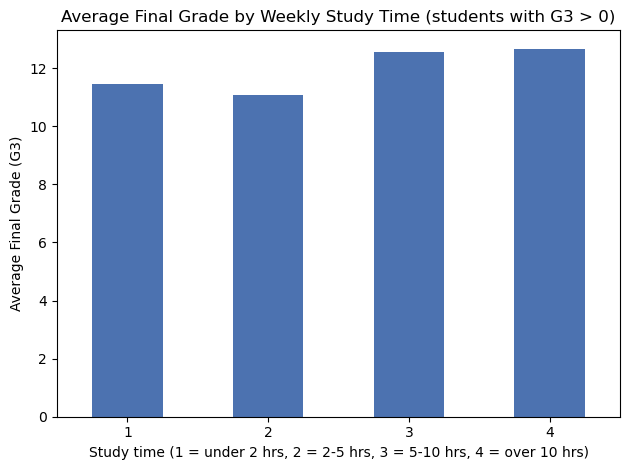

In [14]:
df_no_zero.groupby("studytime")["G3"].mean().plot(kind="bar", color="#4C72B0")
plt.title("Average Final Grade by Weekly Study Time (students with G3 > 0)")
plt.xlabel("Study time (1 = under 2 hrs, 2 = 2-5 hrs, 3 = 5-10 hrs, 4 = over 10 hrs)")
plt.ylabel("Average Final Grade (G3)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Among students with G3 > 0, average final grade does not rise steadily with weekly study
time. Students studying under 2 hours average 11.47 and those studying 2-5 hours average
11.07, while those studying 5-10 hours average 12.56 and those studying over 10 hours
average 12.67. The overall difference between the lowest and highest group is about 1.6
points out of 20, which is small. The highest group has only 24 students, so its average
should be read with caution. Study time is associated with grades here, but this data does
not show that it causes them.

In [15]:
#3.Do students with past failures perform worse?

df_no_zero.groupby("failures")["G3"].agg(["count", "mean"]).round(2)

,count,mean
failures,,
0,294,11.94
1,40,10.15
2,12,8.83
3,11,8.27


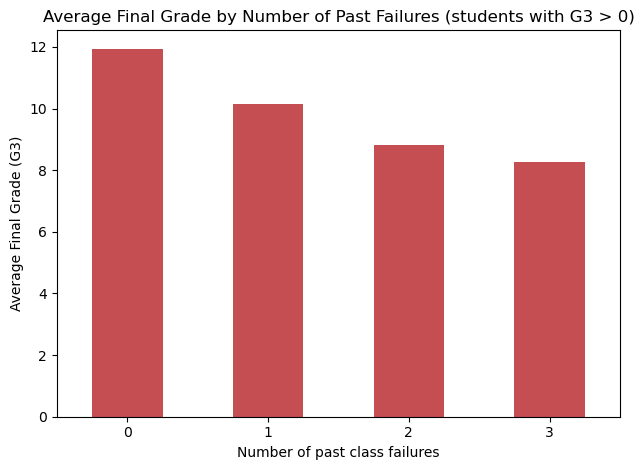

In [16]:
df_no_zero.groupby("failures")["G3"].mean().plot(kind="bar", color="#C44E52")
plt.title("Average Final Grade by Number of Past Failures (students with G3 > 0)")
plt.xlabel("Number of past class failures")
plt.ylabel("Average Final Grade (G3)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Among students with G3 > 0, average final grade falls steadily as the number of past
class failures rises: 11.94 for students with no past failures (n = 294), 10.15 with one
(n = 40), 8.83 with two (n = 12) and 8.27 with three or more (n = 11). Students with
three or more failures average about 3.7 points lower than those with none, a larger gap
than the one seen for study time. The groups with two or more failures are small, so
their averages should be read with caution. This shows an association, not that past
failures cause lower grades.

In [17]:
#4.What share of students pass, and what do students at risk have in common?

df_no_zero = df_no_zero.copy()
df_no_zero["passed"] = df_no_zero["G3"] >= PASS_MARK

summary = df_no_zero.groupby("passed")[["absences", "studytime", "failures"]].mean().round(2)
summary["students"] = df_no_zero["passed"].value_counts()
summary

,absences,studytime,failures,students
passed,,,,
False,9.55,1.93,0.60,92
True,5.19,2.08,0.16,265


In [18]:
(df_no_zero["failures"] > 0).groupby(df_no_zero["passed"]).mean().mul(100).round(1)

passed
False    34.8
True     11.7
Name: failures, dtype: float64

In [19]:
df_no_zero.groupby("passed")["absences"].median()

passed
False    6.0
True     4.0
Name: absences, dtype: float64

Of the 357 students with G3 > 0, 265 (74.2%) passed and 92 did not (final grade 1-9).
Compared with students who passed, those who did not pass had more past failures on
average (0.60 vs 0.16) and higher average absences (9.55 vs 5.19), and 34.8% of them had
at least one past failure compared with 11.7% of those who passed. Average study time
group was similar (1.93 vs 2.08). These are associations in observational data, not
proof of what causes a student not to pass.

# Extra: early-warning check - does a low first-period grade (G1) flag students who later don't pass?

In [20]:

df_no_zero = df_no_zero.copy()
df_no_zero["passed"] = df_no_zero["G3"] >= PASS_MARK
df_no_zero["low_g1"] = df_no_zero["G1"] < PASS_MARK
df_no_zero.groupby("low_g1")["passed"].agg(["count", "mean"]).assign(mean=lambda x: (x["mean"] * 100).round(1))

,count,mean
low_g1,,
False,246,92.3
True,111,34.2


Among the 357 students with G3 > 0, 92.3% of those with a first-period grade of 10 or above
(n = 246) went on to pass, compared with 34.2% of those with a first-period grade below 10
(n = 111). A low first-period grade is therefore a useful early indicator for review. This is
expected, because G1 and G3 are grades from the same course, so it is a practical check
rather than a surprising finding. It shows an association and does not predict any individual
student's result.

## Conclusion

**Findings**
- 67.09% of all 395 students passed (G3 >= 10); excluding the 38 students with G3 = 0,
  the pass rate is 74.23%.
- The 38 zero-grade students all have 0 recorded absences, which hid the absences pattern.
  Without them, absences show a weak negative association with final grade (-0.21).
- Past failures show the strongest pattern: average grade falls from 11.94 (no failures)
  to 8.27 (three or more).
- Study time shows only a small, uneven difference in grades.
- Students who did not pass had more past failures and higher absences than those who
  passed.
- The pass rate depends strongly on the pass mark chosen: about 82% at a pass mark of 8,
  67% at 10 and about 41% at 12. Pass percentages from this project should be read with
  that rule in mind.
- A first-period grade below 10 is a strong early indicator: 34.2% of those students went on to
  pass, compared with 92.3% of those who scored 10 or above in the first period.

**Recommendations** (for review, not proven causes)
- Offer early support to students with past failures.
- Monitor students with high absences.
- Check why 38 students have a final grade of 0 with no recorded absences.
- Use the first-period grade as an early trigger for review, so support starts before the final grade.

**Limitations**
- The data is observational, so it shows associations, not causes.
- It covers one course (mathematics) in two schools, so it may not apply elsewhere.
- The pass mark of 10 is my own rule; the dataset does not define one.
- The zero grades are unexplained, and some groups are small (for example, 11 and 12
  students with two or three failures).